1. Cel analizy
Zrozumieć, co różnicuje liczbę streamów utworów/artystów w latach 2020-2025 oraz ile z tego da się wyjaśnić cechami samego utworu (gatunek, cechy audio, moment premiery), a ile leży poza nimi (marka artysty, promocja, playlisty).

Trzy osie analizy:
Opis rynku: rozkład i koncentracja streamów.
Różnice i trendy: gatunki, czas premiery, ewolucja cech audio.
Modelowanie: ile wariancji w streamach wyjaśniają dostępne cechy.

In [60]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [61]:
folder = Path.cwd()
file = folder / "spotify_artist_streaming_2020_2025.csv"

df = pd.read_csv(file)

print(f'Tabela posiada {df.shape[0]} wierszy oraz {df.shape[1]} kolumny.')
display(df.head())

Tabela posiada 50000 wierszy oraz 33 kolumny.


,track_id,track_name,artist_name,album_name,release_date,genre,duration_ms,popularity,danceability,energy,...,popularity_category,loudness_category,key_name,mode_name,is_explicit_bool,release_quarter,is_weekend_release,log_stream_count,upbeat_score,artist_track_count
0,346d85e2-ffde-41b3-854a-589ed880b91f,Storm,Ethereal,The Hollow Journeys,2021-10-06,Pop,169594,47,0.6777,0.7949,...,Medium,Loud,A,Major,False,Q4,False,10.7492,0.6632,3232
1,12bc268a-363b-4f19-8fa8-0ced7ae1e462,Silent,The Wolfs,Ancient Thunder,2024-10-26,K-Pop,256755,26,0.9405,0.7163,...,Medium,Moderate,C#,Major,False,Q4,True,8.5895,0.7615,20
2,30d627d9-878d-4bb3-be59-71feb6ed4f3f,Shattered Lines,LolaOre,Twisted Harbors,2022-11-12,Punk,170212,46,0.6853,0.9500,...,Medium,Loud,E,Major,False,Q4,True,12.2935,0.7828,199
3,85501bb9-d221-4339-9e2e-29b1b3daff0a,Breaking Roses,Clay Black,The Blinding Letters,2020-06-22,Pop,181250,4,0.7817,0.6943,...,Low,Moderate,F#,Major,False,Q2,False,8.5658,0.6778,693
4,7bf92bd2-c6fe-4869-a90e-242bb8bbe7a3,Lines,Knot Hart,The Cosmic Letters,2024-01-22,Latin,160894,27,0.7200,0.4958,...,Medium,Moderate,C#,Major,False,Q1,False,10.2191,0.5494,12111


In [62]:
df = df.drop(columns= {'duration_ms','key','popularity','mode'})
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   track_id             50000 non-null  object 
 1   track_name           50000 non-null  object 
 2   artist_name          50000 non-null  object 
 3   album_name           50000 non-null  object 
 4   release_date         50000 non-null  object 
 5   genre                50000 non-null  object 
 6   danceability         50000 non-null  float64
 7   energy               50000 non-null  float64
 8   loudness             50000 non-null  float64
 9   instrumentalness     50000 non-null  float64
 10  tempo                50000 non-null  float64
 11  stream_count         50000 non-null  int64  
 12  country              50000 non-null  object 
 13  explicit             50000 non-null  bool   
 14  label                50000 non-null  object 
 15  release_year         50000 non-null 

In [63]:
typy = ['number','object','bool','datetime']

for typ in typy:
    print("=="*50)
    print(f"Kolumny typu {typ}, liczba: {df.select_dtypes(include=typ).shape[1]}")
    print("=="*50)
    display(df.select_dtypes(include=typ).head(3))
    

Kolumny typu number, liczba: 12


,danceability,energy,loudness,instrumentalness,tempo,stream_count,release_year,release_month,duration_minutes,log_stream_count,upbeat_score,artist_track_count
0,0.6777,0.7949,-2.90,0.0065,111.89,46592,2021,10,2.83,10.7492,0.6632,3232
1,0.9405,0.7163,-7.72,0.0198,129.17,5374,2024,10,4.28,8.5895,0.7615,20
2,0.6853,0.9500,-2.38,0.0103,150.06,218262,2022,11,2.84,12.2935,0.7828,199


Kolumny typu object, liczba: 14


,track_id,track_name,artist_name,album_name,release_date,genre,country,label,release_day_of_week,popularity_category,loudness_category,key_name,mode_name,release_quarter
0,346d85e2-ffde-41b3-854a-589ed880b91f,Storm,Ethereal,The Hollow Journeys,2021-10-06,Pop,US,Self-Released,Wednesday,Medium,Loud,A,Major,Q4
1,12bc268a-363b-4f19-8fa8-0ced7ae1e462,Silent,The Wolfs,Ancient Thunder,2024-10-26,K-Pop,ES,Prism Audio,Saturday,Medium,Moderate,C#,Major,Q4
2,30d627d9-878d-4bb3-be59-71feb6ed4f3f,Shattered Lines,LolaOre,Twisted Harbors,2022-11-12,Punk,US,Columbia Records,Saturday,Medium,Loud,E,Major,Q4


Kolumny typu bool, liczba: 3


,explicit,is_explicit_bool,is_weekend_release
0,False,False,False
1,False,False,True
2,False,False,True


Kolumny typu datetime, liczba: 0


""
0
1
2


In [64]:
kolumny_category_przed = df[['genre','popularity_category','loudness_category']].memory_usage(deep=True).sum()

In [65]:
df['release_date'] = pd.to_datetime(df['release_date'])
df[df.select_dtypes(include='object').columns] =  df.select_dtypes(include='object').astype('string')
df[['genre','popularity_category','loudness_category']] = df[['genre','popularity_category','loudness_category']].astype('category')
df[df.select_dtypes(include='number').columns] = df[df.select_dtypes(include='number').columns].apply(
    lambda x: pd.to_numeric(x, downcast='integer')
    if x.dtype == 'int64'
    else pd.to_numeric(x, downcast='float')
    if x.dtype == 'float64'
    else x
)
df

,track_id,track_name,artist_name,album_name,release_date,genre,danceability,energy,loudness,instrumentalness,...,popularity_category,loudness_category,key_name,mode_name,is_explicit_bool,release_quarter,is_weekend_release,log_stream_count,upbeat_score,artist_track_count
0,346d85e2-ffde-41b3-854a-589ed880b91f,Storm,Ethereal,The Hollow Journeys,2021-10-06,Pop,0.6777,0.7949,-2.90,0.0065,...,Medium,Loud,A,Major,False,Q4,False,10.7492,0.6632,3232
1,12bc268a-363b-4f19-8fa8-0ced7ae1e462,Silent,The Wolfs,Ancient Thunder,2024-10-26,K-Pop,0.9405,0.7163,-7.72,0.0198,...,Medium,Moderate,C#,Major,False,Q4,True,8.5895,0.7615,20
2,30d627d9-878d-4bb3-be59-71feb6ed4f3f,Shattered Lines,LolaOre,Twisted Harbors,2022-11-12,Punk,0.6853,0.9500,-2.38,0.0103,...,Medium,Loud,E,Major,False,Q4,True,12.2935,0.7828,199
3,85501bb9-d221-4339-9e2e-29b1b3daff0a,Breaking Roses,Clay Black,The Blinding Letters,2020-06-22,Pop,0.7817,0.6943,-8.00,0.0151,...,Low,Moderate,F#,Major,False,Q2,False,8.5658,0.6778,693
4,7bf92bd2-c6fe-4869-a90e-242bb8bbe7a3,Lines,Knot Hart,The Cosmic Letters,2024-01-22,Latin,0.7200,0.4958,-6.38,0.0372,...,Medium,Moderate,C#,Major,False,Q1,False,10.2191,0.5494,12111
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,38913908-e3ab-42a2-9a97-2d1847c21e3b,Flames,Luna Ink,The Shattered Tapes,2025-02-27,Hip-Hop,0.7338,0.8172,-2.65,0.0094,...,Low,Loud,C#,Major,False,Q1,False,6.2005,0.7545,577
49996,83653402-ca85-4583-b7ec-13ab3e82888e,Love,Knot Hart,Young II,2021-07-25,Folk,0.5547,0.0000,-15.54,0.0644,...,Low,Quiet,A#,Minor,True,Q3,True,9.1916,0.3292,12111
49997,4398dd33-ecfc-4c1a-ab9e-248f38082318,The Waves,Jasper Jade,The Burning Journeys,2023-12-24,Pop,0.6558,0.8805,-6.60,0.0217,...,Low,Moderate,G,Major,True,Q4,True,7.8200,0.6794,181
49998,07c673e7-39a5-4c28-8789-163ae5f17f3f,Flying Eyes,ElaraRain,Frequencies,2020-08-17,Rock,0.5979,0.6252,-6.38,0.0956,...,Very High,Moderate,F#,Minor,False,Q3,False,15.1911,0.5622,1111


In [67]:
df['stream_count'].max()

np.int32(43345015)

In [68]:
kolumny_category_po  = df[['genre','popularity_category','loudness_category','explicit']].memory_usage(deep=True).sum()
kolumny_category_po - kolumny_category_przed
print(
    'Dzięki zamianie wybranych kolumn tekstowych na category udało się zmniejszyć '
    'zużycie pamięci o: '
    f'{(kolumny_category_przed - kolumny_category_po) / 1024**2:.1f} MB - '
    f'{(1 - kolumny_category_po / kolumny_category_przed) * 100:.1f}%'
)


Dzięki zamianie wybranych kolumn tekstowych na category udało się zmniejszyć zużycie pamięci o: 7.5 MB - 97.5%


In [69]:
df = df.apply(lambda col: col.str.strip() if col.dtype == 'string' else col)
missing_values = ['', ' ', 'N/A', 'NA', 'NULL', 'null', '-', 'None']

df = df.replace(missing_values, pd.NA)

mask_puste = df.isna().all(axis=1)
mask_czesciowo_puste = df.isna().any(axis=1) & ~mask_puste

if mask_puste.any():
    print(f"Całkowicie puste wiersze: {mask_puste.sum()}")
    display(df.loc[mask_puste])

    df = df.loc[~mask_puste].copy()

if mask_czesciowo_puste.any():
    print(f"Częściowo puste wiersze: {mask_czesciowo_puste.sum()}")
    display(df.loc[mask_czesciowo_puste])

    print("Braki według kolumn:")
    display(df.loc[mask_czesciowo_puste].isna().sum().loc[lambda x: x.gt(0)].sort_values(ascending=False))

df.reset_index(drop=True, inplace=True)

if not mask_puste.any() and not mask_czesciowo_puste.any():
    print("Brak pustych wierszy")

Brak pustych wierszy


In [70]:
liczba_duplikatów = df.duplicated().sum()

if liczba_duplikatów>0:
    print(f'Liczba zduplikowanych wierszy wynosi: {df.duplicated().sum()}')
    display(df[df.duplicated(keep=False)]) #keep=False zostawia wszystkie wystąpienia zduplikowanych wierszy
else: 
    print('Brak zduplikowanych wierszy.')

Brak zduplikowanych wierszy.


In [85]:
zduplikowane_utwory = len(df[df.duplicated(subset = 'track_id')])
assert zduplikowane_utwory == 0 , f"Lista zawiera zduplikowane {zduplikowane_utwory} utwory."

In [71]:
summary = df.describe(include="number").T
summary["range"] = summary["max"] - summary["min"]
summary['CV'] = summary['std'] /summary['mean'] *100
summary['IQR'] = summary['75%'] -summary['25%']
summary

,count,mean,std,min,25%,50%,75%,max,range,CV,IQR
danceability,50000.0,0.661236,0.164143,0.000000,0.562400,0.675000,0.775400,1.000000e+00,1.000000e+00,24.823650,0.213000
energy,50000.0,0.631853,0.168741,0.000000,0.523400,0.633400,0.744700,1.000000e+00,1.000000e+00,26.705655,0.221300
loudness,50000.0,-7.669547,2.621917,-18.620001,-9.440000,-7.660000,-5.880000,0.000000e+00,1.862000e+01,-34.186067,3.559999
instrumentalness,50000.0,0.055166,0.095083,0.000000,0.010300,0.025700,0.057600,1.000000e+00,1.000000e+00,172.359088,0.047300
tempo,50000.0,119.067459,19.647806,60.000000,105.989998,118.575001,131.350006,2.200000e+02,1.600000e+02,16.501407,25.360008
stream_count,50000.0,118378.924280,565844.253326,100.000000,4979.750000,15955.000000,60685.500000,4.334502e+07,4.334492e+07,477.994083,55705.750000
release_year,50000.0,2022.499620,1.709953,2020.000000,2021.000000,2023.000000,2024.000000,2.025000e+03,5.000000e+00,0.084547,3.000000
release_month,50000.0,6.528880,3.460926,1.000000,4.000000,7.000000,10.000000,1.200000e+01,1.100000e+01,53.009483,6.000000
duration_minutes,50000.0,3.496914,0.744101,1.500000,3.000000,3.490000,4.000000,6.470000e+00,4.970000e+00,21.278798,1.000000
log_stream_count,50000.0,9.835506,1.793877,4.615100,8.513350,9.677600,11.013525,1.758470e+01,1.296960e+01,18.238785,2.500175


                                WYKRESY ROZKŁADU ZMIENNYCH NUMERYCZNYCH


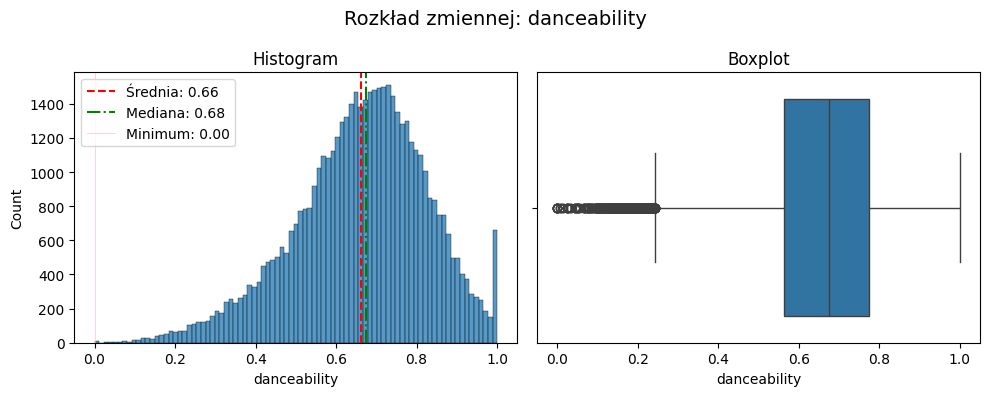

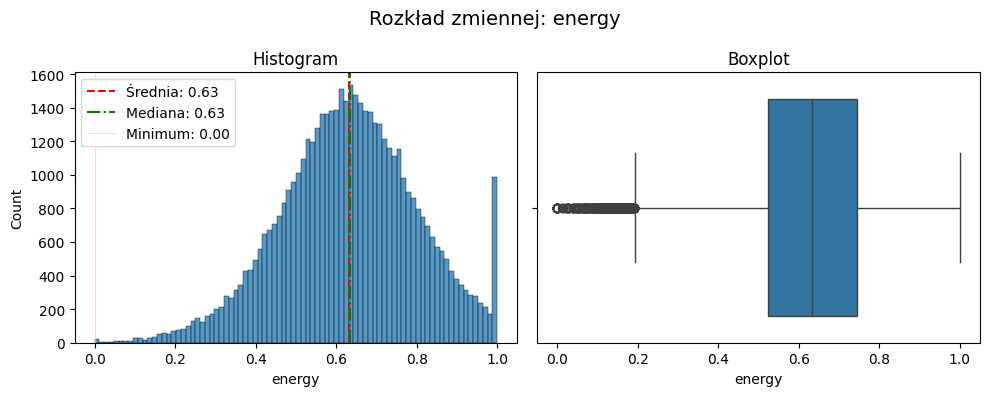

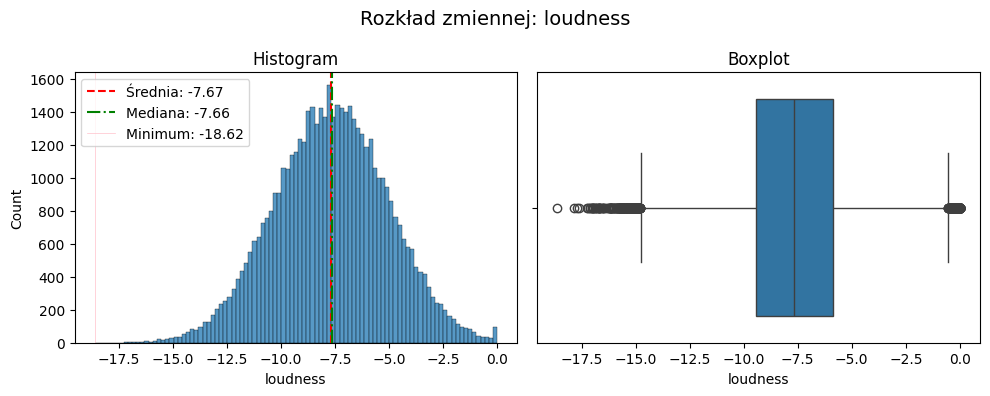

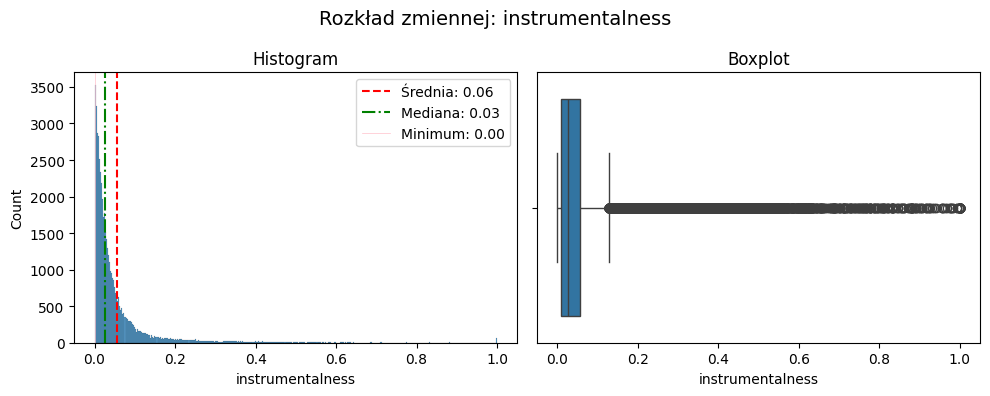

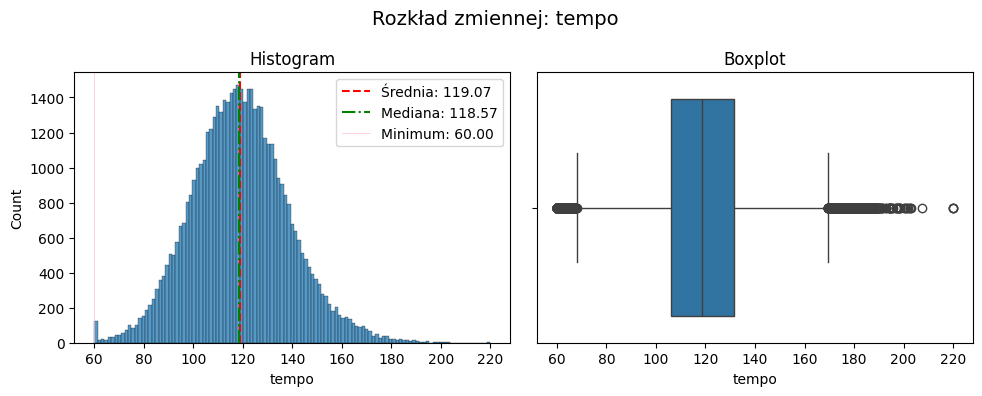

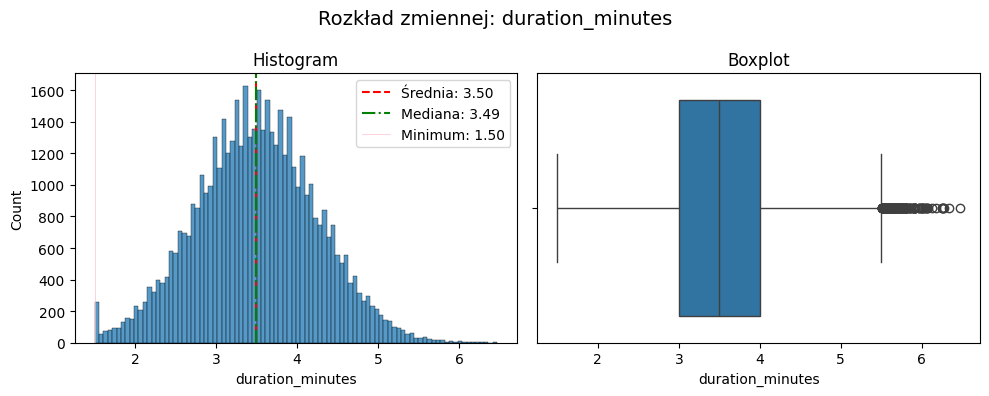

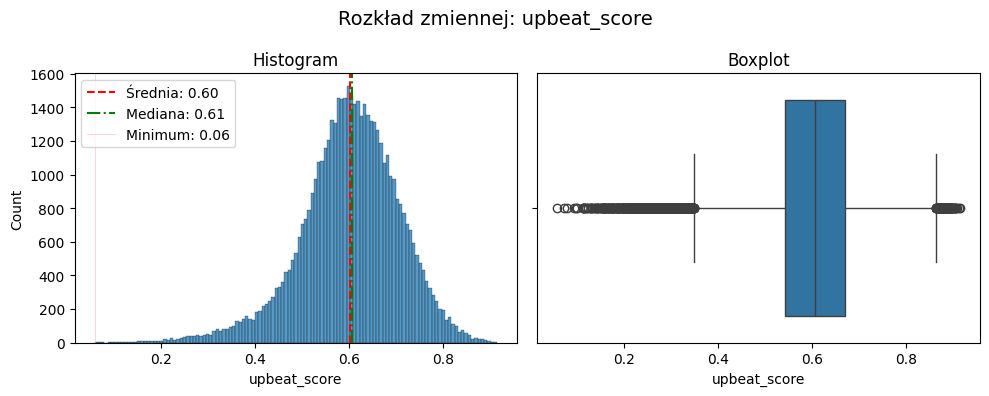

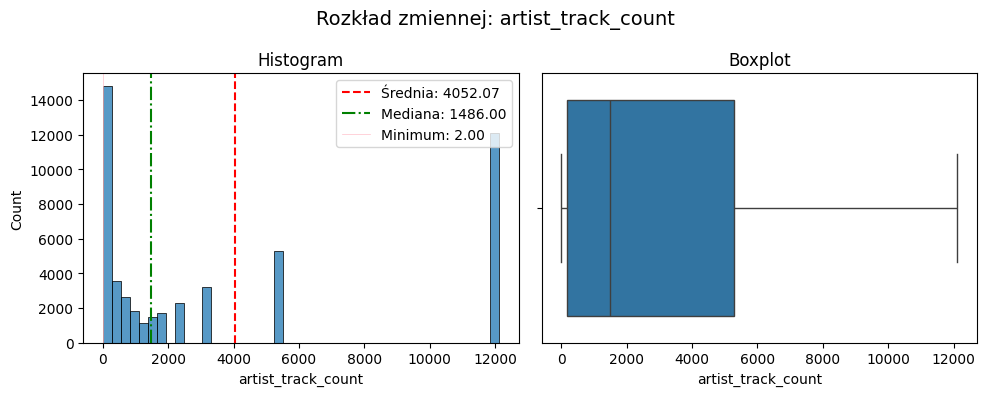

In [72]:
kolumny_numeryczne = df.select_dtypes(include="number").columns.drop(["release_year", "release_month", "stream_count","log_stream_count"], errors="ignore")
#stream_count z racji dużej liczby outlierów powinien być pokazywany w skali logarytmicznej


print("=" * 80)
print("                                WYKRESY ROZKŁADU ZMIENNYCH NUMERYCZNYCH")
print("=" * 80)

for kol in kolumny_numeryczne:

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))

    mean = df[kol].mean()
    median = df[kol].median()
    min = df[kol].min()


    fig.suptitle(f"Rozkład zmiennej: {kol}", fontsize=14)

    sns.histplot(data=df[kol], ax=ax[0])
    ax[0].set_title("Histogram")
    ax[0].axvline(mean, linestyle="--",color = 'red', label=f"Średnia: {mean:.2f}")
    ax[0].axvline(median, linestyle="-.", color = 'green', label=f"Mediana: {median:.2f}")
    ax[0].axvline(min, linestyle="-", linewidth  = .5,color = 'pink', label=f"Minimum: {min:.2f}")
    ax[0].legend()

    sns.boxplot(x=df[kol], ax=ax[1],)
    ax[1].set_title("Boxplot")

    plt.tight_layout()
    plt.show()


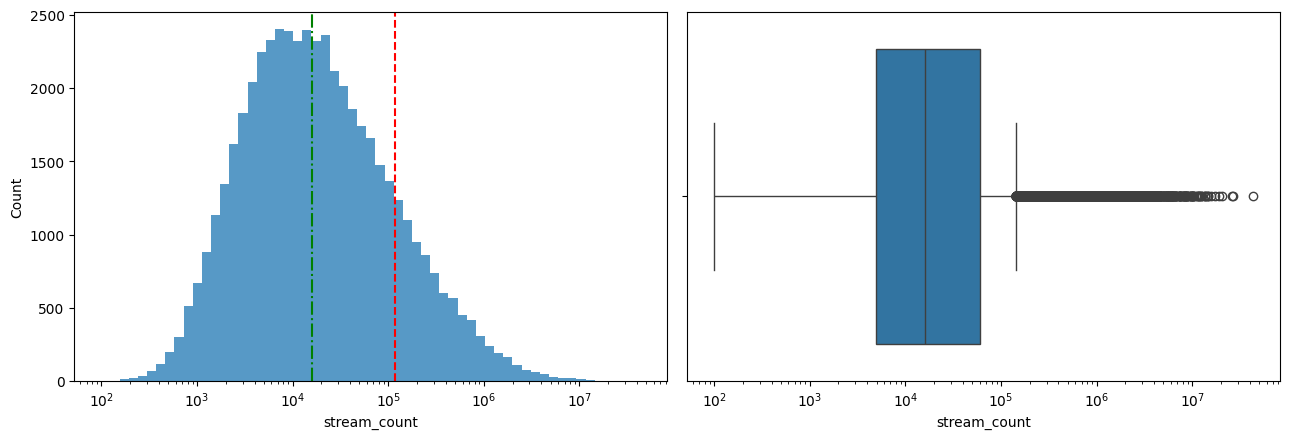

In [73]:
x = df["stream_count"].dropna()
x = x[x > 0]  # log wymaga wartości > 0

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Histogram: biny równe w skali log (NIE liniowe biny na osi log!)
bins = np.logspace(np.log10(x.min()), np.log10(x.max()), 60)
sns.histplot(x, bins=bins, ax=axes[0])
axes[0].set_xscale("log")
axes[0].axvline(x.median(), color="green", ls="-.", label=f"Mediana: {x.median():,.0f}")
axes[0].axvline(x.mean(), color="red", ls="--", label=f"Średnia: {x.mean():,.0f}")

sns.boxplot(x=x, ax=axes[1])
axes[1].set_xscale("log")

plt.tight_layout()

In [74]:
bool_cols = df.select_dtypes(include='bool').columns

bool_summary = pd.DataFrame({
    'count': df[bool_cols].count(),
    'missing': df[bool_cols].isna().sum(),
    'missing_%': df[bool_cols].isna().mean() * 100,
    'true': df[bool_cols].sum(),
    'true_%': df[bool_cols].mean() * 100,
    'false': (~df[bool_cols]).sum(),
    'false_%': (~df[bool_cols]).mean() * 100,
})

bool_summary

,count,missing,missing_%,true,true_%,false,false_%
explicit,50000,0,0.0,12424,24.848,37576,75.152
is_explicit_bool,50000,0,0.0,12424,24.848,37576,75.152
is_weekend_release,50000,0,0.0,14453,28.906,35547,71.094


In [75]:
def string_describe(df, top_n=3):
    cols = df.select_dtypes(include=['object', 'string']).columns

    rows = []

    for col in cols:
        s = df[col]

        row = {
            'column': col,
            'dtype': str(s.dtype),
            'count': s.count(),
            'missing': s.isna().sum(),
            'missing_%': s.isna().mean() * 100,
            'unique': s.nunique(dropna=True),
            'unique_%': s.nunique(dropna=True) / len(df) * 100,
            'avg_length': s.dropna().str.len().mean(),
        }

        top = s.value_counts(dropna=True).head(top_n)

        for i, (value, count) in enumerate(top.items(), 1):
            row[f'top_{i}'] = value
            row[f'top_{i}_%'] = count / s.notna().sum() * 100

        rows.append(row)

    return pd.DataFrame(rows).set_index('column')

string_describe(df)

,dtype,count,missing,missing_%,unique,unique_%,avg_length,top_1,top_1_%,top_2,top_2_%,top_3,top_3_%
column,,,,,,,,,,,,,
track_id,string,50000,0,0.0,50000,100.000,36.00000,6b2ea6b8-c215-4588-b039-ee341715f76e,0.002,65df879c-f063-477d-8659-65c5d6806a1c,0.002,0331119f-340d-40bc-a9b3-7430451e5b5b,0.002
track_name,string,50000,0,0.0,8895,17.790,10.88784,Memories,0.610,Shadows,0.608,Islands,0.600
artist_name,string,50000,0,0.0,500,1.000,9.19460,Knot Hart,24.222,IsleEyre,10.542,Ethereal,6.464
album_name,string,50000,0,0.0,4019,8.038,11.07906,Notes,0.712,Journeys,0.702,Files,0.698
country,string,50000,0,0.0,30,0.060,2.00000,US,19.966,GB,7.926,BR,6.074
label,string,50000,0,0.0,30,0.060,14.44882,Catalyst Records,3.838,Cipher Music,3.838,Wavelength Records,3.810
release_day_of_week,string,50000,0,0.0,7,0.014,7.15076,Wednesday,14.580,Saturday,14.522,Sunday,14.384
key_name,string,50000,0,0.0,12,0.024,1.41822,E,8.590,D#,8.518,C#,8.514
mode_name,string,50000,0,0.0,2,0.004,5.00000,Major,65.028,Minor,34.972,NaN,NaN


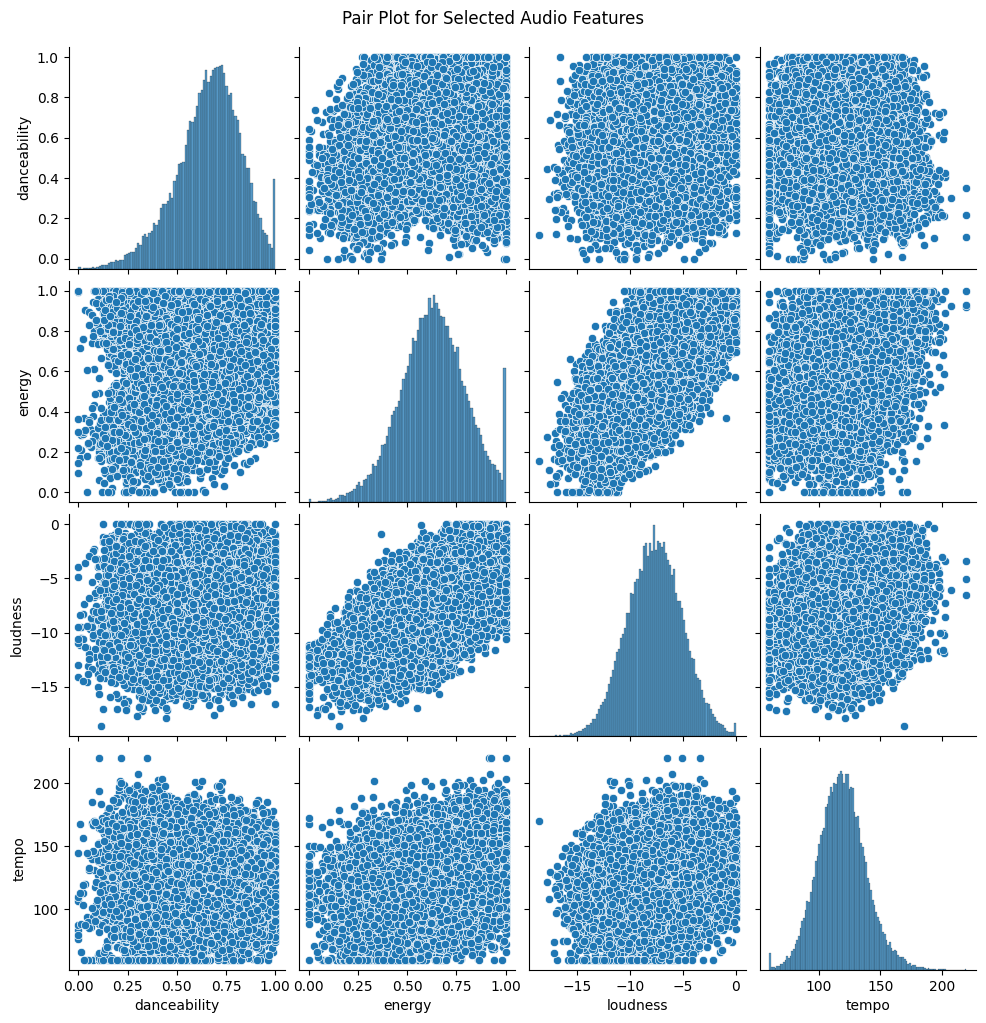

In [ ]:
selected_features = ['danceability', 'energy', 'loudness', 'tempo']
if set(selected_features).issubset(df.columns): #sprawdza czy kolumny istenieją w df
    sns.pairplot(df[selected_features])
    plt.suptitle('Pair Plot for Selected Audio Features', y=1.02) 
    plt.show()

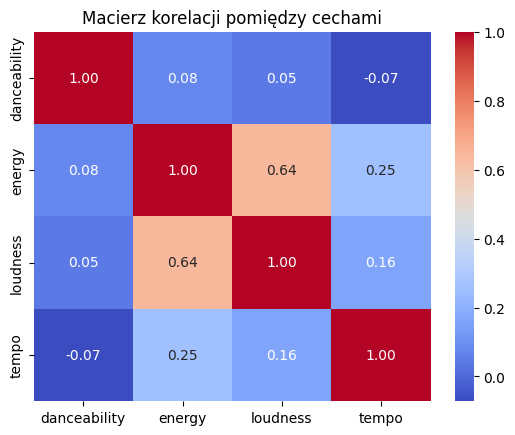

In [87]:
sns.heatmap(df[selected_features].corr(),annot=True,cmap='coolwarm',fmt='.2f')


plt.title('Macierz korelacji pomiędzy cechami')
plt.show()